In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#### Loading the dataset

In [12]:
titanic = sns.load_dataset('titanic')         # load_dataset helps in loading the dataset stored as csv files

In [13]:
# Printing the type of the datset to know what is loaded using seaborn
type(titanic)

pandas.core.frame.DataFrame

In [14]:
titanic

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


**Dataframe:** Tabular representation of data

## **Univariate Analysis**
It focuses on the distribution of a single variable.

Ques 1. What is the average age of passengers?

In [45]:
# Picking a single column from pandas dataframe
# Syntax - dataframe['column name']

print(f"Average Age of Passengers: {titanic['age'].mean():.2f}")

Average Age of Passengers: 29.70


Ques 2. What is the most common passenger class?

In [34]:
type(titanic['pclass'].mode())

pandas.core.series.Series

In [38]:
print(f"Most Common Passenger Class: {titanic['pclass'].mode()[0]}")

Most Common Passenger Class: 3


Ques 3. What is the range of ticket fares?

In [40]:
# range = max-min
min = titanic['fare'].min()
max = titanic['fare'].max()

In [41]:
min, max

(0.0, 512.3292)

In [44]:
range = max-min
print(f"Range of Fair Column: {range:.2f}")

Range of Fair Column: 512.33


Ques 4. What is the median fare paid by passengers?

In [49]:
print(f"Median Fare by Passengers: ${titanic['fare'].median():.2f}")

Median Fare by Passengers: $14.45


Ques 5. What is the mode of embarkation ports?

In [52]:
titanic['embarked'].mode()[0]

'S'

or

In [56]:
print(f"Mode of Embarked Port is: {titanic['embark_town'].mode()[0]}")

Mode of Embarked Port is: Southampton


Ques 6. What is the mean absolute deviation (MAD) for passenger ages?

In [70]:
titanic['age'].head()

0    22.0
1    38.0
2    26.0
3    35.0
4    35.0
Name: age, dtype: float64

In [71]:
titanic['age'].mean()

29.69911764705882

In [74]:
def mad(col):
    age_mean = col.mean()
    avg = np.abs(col - age_mean).mean()
    return avg

In [77]:
avg = mad(titanic['age'])
print(f"Mean Absolute Deviation of Age Column: {avg:.2f}")

Mean Absolute Deviation of Age Column: 11.32


Ques 7. What is the standard deviation for ticket fares?

In [78]:
standard_deviation = titanic['fare'].std()
print(f"Standard Deviation for Ticket Fares: {standard_deviation:.2f}")

Standard Deviation for Ticket Fares: 49.69


Ques 8. What is the 25th and 75th percentile of Age column?

In [82]:
percentile_25 = titanic['age'].quantile(0.25)
percentile_75 = titanic['age'].quantile(0.75)

In [83]:
print(f"25th Percentile of Age: {percentile_25:.2f}")
print(f"75th Percentile of Age: {percentile_75:.2f}")

25th Percentile of Age: 20.12
75th Percentile of Age: 38.00


Ques 9. Is the distribution of ticket fares skewed?

In [92]:
print(f"Skewness of Ticket Fares: {titanic['fare'].skew():.2f}")

Skewness of Ticket Fares: 4.79


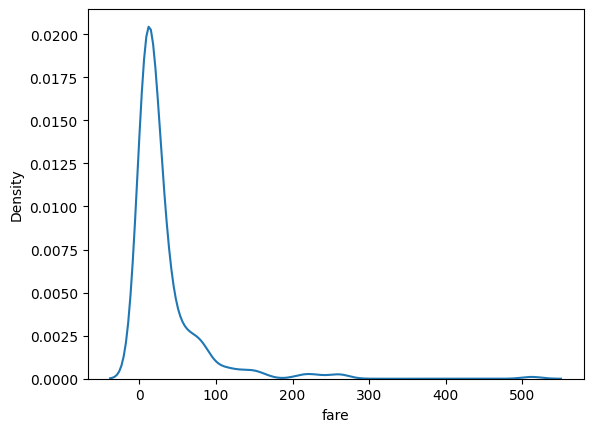

In [93]:
sns.kdeplot(x='fare',data=titanic)
plt.show()

Ques 10. What is the kurtosis of ticket fares?

In [91]:
print(f"Skewness of Ticket Fares: {titanic['fare'].kurt():.2f}")

Skewness of Ticket Fares: 33.40


<hr>

## **Bivariate Analysis**
Bivariate analysis examines the relationship between two variables.

Ques 1. What is the covariance between age and fare?

In [103]:
covariance = titanic[['age','fare']].cov()
print("Covariance Matrix:")
print(covariance)

Covariance Matrix:
             age         fare
age   211.019125    73.849030
fare   73.849030  2469.436846


Ques 2. What is the correlation between age and fare?

In [110]:
correlation = titanic[['age','fare']].corr()
print("Correlation Matrix:")
print(correlation)

Correlation Matrix:
           age      fare
age   1.000000  0.096067
fare  0.096067  1.000000


<hr>

## **Multivariate Analysis**
Multivariate analysis involves relationships among three or more variables.

Ques 1. What is the covariance between  age, class, fare and survived?

In [111]:
covariance = titanic[['age', 'fare', 'pclass', 'survived']].cov()
print("Covariance Matrix:")
print(covariance)

Covariance Matrix:
                 age         fare     pclass  survived
age       211.019125    73.849030  -4.496004 -0.551296
fare       73.849030  2469.436846 -22.830196  6.221787
pclass     -4.496004   -22.830196   0.699015 -0.137703
survived   -0.551296     6.221787  -0.137703  0.236772


Ques 2. What is the correlation between  age, class, fare and survived?

In [114]:
correlation = titanic[['age', 'fare', 'pclass', 'survived']].corr()
print("Correlation Matrix:")
print(correlation)

Correlation Matrix:
               age      fare    pclass  survived
age       1.000000  0.096067 -0.369226 -0.077221
fare      0.096067  1.000000 -0.549500  0.257307
pclass   -0.369226 -0.549500  1.000000 -0.338481
survived -0.077221  0.257307 -0.338481  1.000000
